# PA2 · Question 2 · Step 6: models A–D (Table 5) and the final model (Table 6, Figure 6)

| Handout item | What | Section |
|---|---|---|
| **Q2.12 evidence** | one-step reach of model A and model D, measured (not only counted) | 2 |
| **Table 5** | for A, B, C, D: $E^{(5)}$ at 1×; $C_M, E_M, C_R, E_R$; $E^{(2)}$ at 1×, 2×, 3×; parameters; training time per epoch; inference time | 3 |
| **Table 6** | the same columns for symmetrised B and symmetrised D ($C_M$, $C_R$ in scientific notation) | 5 |
| **Figure 6** | (a) Figure 3 repeated with the final model on the same 4 videos **+ GIFs**; (b) Figure 5 repeated on the same video | 6 |
| *extra (optional)* | the Q2.7 video with A, D and the final model side by side, for Q2.16 | 7 |

You write **one** small part (✏️ YOUR TURN): the symmetrised forecaster $\bar f$ (Section 4).

### Before you start
1. **Inputs.** Make one Kaggle dataset (Add Input → Upload → New Dataset) with these files, or add them to your existing checkpoint dataset as a new version:
   * checkpoints: `A_seed0.pt`, `A_seed1.pt`, `B_seed0.pt`, `B_seed1.pt`, `C_seed0.pt`, `C_seed1.pt`, `D_seed0.pt`, `D_seed1.pt`
   * training logs: `A_seed0.json`, `A_seed1.json`, `B_seed0.json`, …, `D_seed1.json` (they hold the training time per epoch)
   * optional: `figure_videos.json` from Step 5 (otherwise the video numbers in the CONFIG cell are used)

   If a browser renamed a `.pt` file to `.zip`, rename it back to `.pt` **before** uploading (Kaggle unpacks `.zip` files).
2. **Settings:** Accelerator **GPU T4** (the same hardware as your training, so the times are comparable), Internet **On**.

In [1]:
import os, glob, json, time, io
import numpy as np
import torch, torchvision
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
HARDWARE = torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"
print("torch", torch.__version__, "| device:", device, "|", HARDWARE)

OUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "./outputs"
RES_DIR, GIF_DIR = os.path.join(OUT_DIR, "results"), os.path.join(OUT_DIR, "gifs")
os.makedirs(RES_DIR, exist_ok=True); os.makedirs(GIF_DIR, exist_ok=True)

# ---- CONFIG ----
MODELS      = ["A", "B", "C", "D"]     # learned models in Table 5 (add "DB" here if you also trained D+B)
FINAL_BASE  = "D"                      # final model = symmetrised D (the handout's default); "DB" only if you trained D+B
FIG3_PANELS = [("M", 1, 269), ("M", 2, 499), ("R", 1, 31), ("R", 2, 150)]   # your Figure 3 videos (Step 5)
FIG5_VIDEO  = 21                       # your Figure 5 video (Step 5)
Q27_VIDEO   = ("R", 150)               # the video you discussed in Q2.7 (for the optional Q2.16 figure)
# used ONLY if a training-log file is missing (seconds per epoch, (seed 0, seed 1)), copied from your logs:
TRAIN_TIME_FALLBACK = {"A": (10.9, 11.2), "B": (10.771, 10.878), "C": (10.534, 10.541)}

torch 2.11.0+cu128 | device: cuda | Tesla T4


## 1. Data, functions, models A and D, and the trained weights

In [2]:
ON_KAGGLE = os.path.exists("/kaggle/input")
DATA_ROOT = "/tmp/mmnist" if ON_KAGGLE else "./data"
found = glob.glob("/kaggle/input/**/mnist_test_seq.npy", recursive=True) if ON_KAGGLE else []
if found:
    os.makedirs(os.path.join(DATA_ROOT, "MovingMNIST"), exist_ok=True)
    link = os.path.join(DATA_ROOT, "MovingMNIST", "mnist_test_seq.npy")
    if not os.path.exists(link):
        os.symlink(found[0], link)
ds = torchvision.datasets.MovingMNIST(root=DATA_ROOT, split=None, download=True)
videos_u8 = ds.data if hasattr(ds, "data") else torch.stack([ds[i] for i in range(len(ds))])
assert tuple(videos_u8.shape) == (10000, 20, 1, 64, 64)
videos_dev = videos_u8.to(device)
test_dev = videos_dev[9000:]                     # test videos 9000-9999  ->  numbered 0..999 below
N_TEST = len(test_dev)
print("test videos:", N_TEST)

100%|██████████| 819M/819M [00:23<00:00, 34.6MB/s]


test videos: 1000


In [3]:
# ---- your Step 1 functions ----
def mirror(x):
    return torch.flip(x, dims=[-1])

def rotate(x, a=1):
    return torch.rot90(x, k=a, dims=(-2, -1))

def apply_g(x, a, m):
    y = rotate(x, a)
    return mirror(y) if m else y

def apply_g_inverse(x, a, m):
    y = mirror(x) if m else x
    return rotate(y, -a)

G = [(a, m) for m in (0, 1) for a in range(4)]   # the 8 symmetries (a, m) = M^m R^a
M_T = (0, 1)    # mirror M    = (a=0, m=1)
R_T = (1, 0)    # rotation R  = (a=1, m=0), 90 degrees anticlockwise

# ---- your Step 3 model A ----
class ConvLSTMCell(nn.Module):
    def __init__(self, in_ch, hid_ch, k=3):
        super().__init__()
        self.hid_ch = hid_ch
        self.conv = nn.Conv2d(in_ch + hid_ch, 4 * hid_ch, kernel_size=k, padding=k // 2, bias=True)
    def forward(self, u, h_prev, c_prev):
        z = self.conv(torch.cat([u, h_prev], dim=1))
        i, f, o, g = torch.chunk(z, 4, dim=1)
        c = torch.sigmoid(f) * c_prev + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c

class ModelA(nn.Module):
    def __init__(self, hid=64, patch=4):
        super().__init__()
        self.patch, self.hid = patch, hid
        C = patch * patch
        self.cell1 = ConvLSTMCell(C, hid)
        self.cell2 = ConvLSTMCell(hid, hid)
        self.head  = nn.Conv2d(hid, C, kernel_size=1, bias=True)
    def init_states(self, B, H, W, device):
        return [torch.zeros(B, self.hid, H, W, device=device) for _ in range(4)]
    def step(self, u, states):
        h1, c1, h2, c2 = states
        x = F.pixel_unshuffle(u, self.patch)
        h1, c1 = self.cell1(x, h1, c1)
        h2, c2 = self.cell2(h1, h2, c2)
        pred = torch.sigmoid(F.pixel_shuffle(self.head(h2), self.patch))
        return pred, [h1, c1, h2, c2]
    def forward(self, X):
        B, _, _, H, W = X.shape
        states = self.init_states(B, H // self.patch, W // self.patch, X.device)
        outputs, pred = [], None
        for tau in range(9):
            u = X[:, tau] if tau < 5 else pred
            pred, states = self.step(u, states)
            outputs.append(pred)
        return torch.stack(outputs[4:], dim=1)

# ---- your model D (design D2) - must be exactly the class you trained in Step 4 ----
class ModelD(ModelA):
    # D2: identical to model A, except layer 2's 3x3 convolution is dilated by 3.
    # Reach: 1 cell (layer 1) + 3 cells (layer 2) = 4 cells x 4 px = 16 px.  Parameters: 480,784 (same as A).
    def __init__(self, hid=64, patch=4, dilation=3):
        super().__init__(hid=hid, patch=patch)
        self.cell2.conv = nn.Conv2d(2 * hid, 4 * hid, kernel_size=3,
                                    padding=dilation, dilation=dilation, bias=True)

ARCH = {"A": ModelA, "B": ModelA, "C": ModelA, "D": ModelD, "DB": ModelD}
n_params = lambda m: sum(p.numel() for p in m.parameters())
print("parameters  A:", f"{n_params(ModelA()):,}", "| D:", f"{n_params(ModelD()):,}", "| limit:", f"{int(1.5 * n_params(ModelA())):,}")

# ---- windows and the two reference predictors (same as Step 5) ----
def windows_from_tk(vid_idx, videos, t, k):
    j = torch.arange(10)
    nums  = t[:, None] + j[None, :] * k[:, None]
    valid = nums <= 20
    idx   = (nums.clamp(max=20) - 1).to(videos.device)
    frames = videos[vid_idx.to(videos.device)[:, None], idx].float() / 255.0
    mask = valid[:, 5:].to(videos.device)
    return frames[:, :5], frames[:, 5:] * mask[:, :, None, None, None], mask

def window_batch(b, videos, k=1, t=1, batch=32):
    vid = torch.arange(b, min(b + batch, len(videos)))
    return windows_from_tk(vid, videos, torch.full((len(vid),), t), torch.full((len(vid),), k))

def predict_copy_last(X):
    return X[:, 4:5].expand(-1, 5, -1, -1, -1)

parameters  A: 480,784 | D: 480,784 | limit: 721,176


In [4]:
# ---- load every trained model (both seeds) and its training log ----
def find_file(name):
    hits = []
    for nm in (name, name.replace(".pt", ".zip")) if name.endswith(".pt") else (name,):
        hits += glob.glob(f"/kaggle/input/**/{nm}", recursive=True) + glob.glob(f"./**/{nm}", recursive=True)
    return hits[0] if hits else None

models, train_time, missing = {}, {}, []
for name in MODELS:
    for seed in (0, 1):
        path = find_file(f"{name}_seed{seed}.pt")
        if path is None:
            missing.append(f"{name}_seed{seed}.pt"); continue
        m = ARCH[name]().to(device)
        m.load_state_dict(torch.load(path, map_location=device, weights_only=True))
        m.eval()
        models[(name, seed)] = m
        log_path = find_file(f"{name}_seed{seed}.json")
        if log_path:
            log = json.load(open(log_path))
            if log.get("quick_test"):
                print(f"WARNING: {log_path} comes from a QUICK_TEST run, not the real training.")
            train_time[(name, seed)] = float(log["train_time_per_epoch_s"])
            src = "log"
        elif name in TRAIN_TIME_FALLBACK:
            train_time[(name, seed)] = float(TRAIN_TIME_FALLBACK[name][seed]); src = "fallback (CONFIG)"
        else:
            src = "MISSING"
        print(f"loaded {name} seed {seed}: {path} | train time per epoch from {src}")
if missing:
    print("\nNot found (these rows will be skipped):", missing)
    print("Add them to your input dataset and run this cell again.")
MODELS = [n for n in MODELS if (n, 0) in models and (n, 1) in models]
print("\nmodels in Table 5:", MODELS)

loaded A seed 0: /kaggle/input/datasets/usamaazam9/pa2-checkpoints-abcd/A_seed0.pt | train time per epoch from log
loaded A seed 1: /kaggle/input/datasets/usamaazam9/pa2-checkpoints-abcd/A_seed1.pt | train time per epoch from log
loaded B seed 0: /kaggle/input/datasets/usamaazam9/pa2-checkpoints-abcd/B_seed0.pt | train time per epoch from log
loaded B seed 1: /kaggle/input/datasets/usamaazam9/pa2-checkpoints-abcd/B_seed1.pt | train time per epoch from log
loaded C seed 0: /kaggle/input/datasets/usamaazam9/pa2-checkpoints-abcd/C_seed0.pt | train time per epoch from log
loaded C seed 1: /kaggle/input/datasets/usamaazam9/pa2-checkpoints-abcd/C_seed1.pt | train time per epoch from log
loaded D seed 0: /kaggle/input/datasets/usamaazam9/pa2-checkpoints-abcd/D_seed0.pt | train time per epoch from log
loaded D seed 1: /kaggle/input/datasets/usamaazam9/pa2-checkpoints-abcd/D_seed1.pt | train time per epoch from log

models in Table 5: ['A', 'B', 'C', 'D']


In [5]:
# ---- number formatting required by the handout ----
def fmt(x):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return "n/a"
    if x == 0:
        return "0"
    if abs(x) < 1e-3:
        return f"{x:.2e}"
    return f"{x:#.3g}".rstrip(".")

def fmt_sci(x):                      # Table 6 asks for C_M and C_R in scientific notation
    return f"{x:.2e}"

def fmt_seeds(v0, v1, f=fmt):
    if v0 is None or v1 is None:
        return "n/a"
    return f"{f((v0 + v1) / 2)} ({f(v0)}, {f(v1)})"

def save_table(name, header, rows):
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    text = "\n".join(lines)
    with open(os.path.join(RES_DIR, f"{name}.md"), "w") as f:
        f.write(text + "\n")
    print(text)

## 2. Q2.12 evidence: measured one-step reach of model A and model D (just run)

Q2.12 asks you to estimate D's reach the same way as in Q2.3 (by counting convolutions on each path). This cell **checks your count by measurement**: it runs **one step** of the untrained network, takes the gradient of one output cell, and marks every input cell that can change it. Following the handout's conventions, distance is counted centre-to-centre in grid cells and multiplied by the 4 px per cell.

Paths, as in Q2.3: from the new input $u_\tau$, from layer 1's previous state $h^{(1)}_{\tau-1}$, and from layer 2's previous state $h^{(2)}_{\tau-1}$. The reach is the longest of them.

In [6]:
def one_step_reach(model):
    torch.manual_seed(0)
    P, hid = model.patch, model.hid
    Gs = 64 // P
    u  = torch.rand(1, 1, 64, 64, requires_grad=True)
    h1 = torch.rand(1, hid, Gs, Gs, requires_grad=True); c1 = torch.rand(1, hid, Gs, Gs)
    h2 = torch.rand(1, hid, Gs, Gs, requires_grad=True); c2 = torch.rand(1, hid, Gs, Gs)
    pred, _ = model.step(u, [h1, c1, h2, c2])
    cy = cx = Gs // 2                                            # one output cell in the middle
    pred[0, 0, cy * P:(cy + 1) * P, cx * P:(cx + 1) * P].sum().backward()
    grads = {"u": F.pixel_unshuffle(u.grad.abs(), P).sum(1)[0],
             "h1": h1.grad.abs().sum(1)[0], "h2": h2.grad.abs().sum(1)[0]}
    out = {}
    for path, g in grads.items():
        ys, xs = torch.nonzero(g > 0, as_tuple=True)
        cells = int(torch.max(torch.maximum((ys - cy).abs(), (xs - cx).abs())))
        offsets = sorted(set((xs - cx).tolist()))
        out[path] = (cells, cells * P, offsets)
    return out

header = ["Model", "from u_τ", "from h1_(τ-1)", "from h2_(τ-1)", "reach (longest path)", "parameters"]
rows = []
for name, cls in [("A", ModelA), ("D", ModelD)]:
    r = one_step_reach(cls().cpu())
    rows.append([name] + [f"{r[p][0]} cells = {r[p][1]} px" for p in ("u", "h1", "h2")]
                + [f"**{max(v[1] for v in r.values())} px**", f"{n_params(cls()):,}"])
    print(f"{name}: horizontal offsets (in cells) that the input u can reach in one step: {r['u'][2]}")
print("\nOne-step reach (measured):\n")
save_table("reach_check", header, rows)
print("\nNo holes means every offset between the smallest and the largest appears in the list above.")

A: horizontal offsets (in cells) that the input u can reach in one step: [-2, -1, 0, 1, 2]
D: horizontal offsets (in cells) that the input u can reach in one step: [-4, -3, -2, -1, 0, 1, 2, 3, 4]

One-step reach (measured):

| Model | from u_τ | from h1_(τ-1) | from h2_(τ-1) | reach (longest path) | parameters |
|---|---|---|---|---|---|
| A | 2 cells = 8 px | 2 cells = 8 px | 1 cells = 4 px | **8 px** | 480,784 |
| D | 4 cells = 16 px | 4 cells = 16 px | 3 cells = 12 px | **16 px** | 480,784 |

No holes means every offset between the smallest and the largest appears in the list above.


## 3. Table 5: models A, B, C, D (just run)

Exactly as in Step 5: test set, $t = 1$. $E^{(5)}$, $C_T$, $E_T$ at 1×; $E^{(2)}$ at 1×, 2×, 3×. Each entry is **mean (seed 0, seed 1)**.

* **Training time** per epoch comes from your Step 4 logs (mean over all 30 epochs).
* **Inference time** is measured here, on this GPU: the time to predict all 1,000 original (1×, $t=1$) test videos at batch size 32, under `model.eval()` and `torch.no_grad()`, starting after each batch is on the device (the inputs are prepared first, then only the forward passes are timed).

This takes a few minutes.

In [7]:
@torch.no_grad()
def per_video_mse(predict, videos, k=1, t=1, batch=32):
    out = []
    for b in range(0, len(videos), batch):
        X, Y, mask = window_batch(b, videos, k, t, batch)
        mse = ((predict(X) - Y) ** 2).mean(dim=(2, 3, 4))
        mse[~mask] = float("nan")
        out.append(mse.cpu())
    return torch.cat(out).numpy()                 # (N, 5), NaN where the target frame does not exist

@torch.no_grad()
def per_video_CE(predict, videos, T, batch=32):   # your Step 5 code
    a, m = T
    C, E = [], []
    for b in range(0, len(videos), batch):
        X, Y, _ = window_batch(b, videos, k=1, t=1, batch=batch)
        TX, TY = apply_g(X, a, m), apply_g(Y, a, m)
        f_TX = predict(TX)                 # transform first, then predict
        T_fX = apply_g(predict(X), a, m)   # predict first, then transform
        c = ((f_TX - T_fX) ** 2).mean(dim=(1, 2, 3, 4))
        e = ((f_TX - TY) ** 2).mean(dim=(1, 2, 3, 4))
        C.append(c.cpu()); E.append(e.cpu())
    return torch.cat(C).numpy(), torch.cat(E).numpy()

def E5(m): return float(np.nanmean(m[:, :5].mean(axis=1)))
def E2(m): return float(np.nanmean(m[:, :2].mean(axis=1)))

def sync():
    if device.type == "cuda": torch.cuda.synchronize()

@torch.no_grad()
def inference_time(predict, batch=32):
    batches = [window_batch(b, test_dev, 1, 1, batch)[0] for b in range(0, N_TEST, batch)]  # inputs already on the device
    predict(batches[0]); sync()                   # warm-up (not timed)
    t0 = time.perf_counter()
    for X in batches:
        predict(X)
    sync()
    return time.perf_counter() - t0

def evaluate(predict):
    r = {f"{k}x": per_video_mse(predict, test_dev, k=k) for k in (1, 2, 3)}
    r["CM"], r["EM"] = per_video_CE(predict, test_dev, M_T)
    r["CR"], r["ER"] = per_video_CE(predict, test_dev, R_T)
    r["inference_s"] = inference_time(predict)
    return r

def summary(r):
    return dict(E5_1x=E5(r["1x"]), CM=float(np.mean(r["CM"])), EM=float(np.mean(r["EM"])),
                CR=float(np.mean(r["CR"])), ER=float(np.mean(r["ER"])),
                E2_1x=E2(r["1x"]), E2_2x=E2(r["2x"]), E2_3x=E2(r["3x"]), inference_s=r["inference_s"])

pv, res = {}, {}
for name in MODELS:
    for seed in (0, 1):
        t0 = time.time()
        r = evaluate(models[(name, seed)])
        res[(name, seed)] = summary(r)
        for key in ("1x", "2x", "3x", "CM", "EM", "CR", "ER"):
            pv[f"{name}{seed}_{key}"] = r[key]
        print(f"{name} seed {seed}: done in {time.time() - t0:.0f} s | E5 1x = {res[(name, seed)]['E5_1x']:.4f}")

COLS = ["E5_1x", "CM", "EM", "CR", "ER", "E2_1x", "E2_2x", "E2_3x"]
HEADER = ["Model", "E(5) 1x", "C_M", "E_M", "C_R", "E_R", "E(2) 1x", "E(2) 2x", "E(2) 3x",
          "Parameters", "Train time / epoch (s)", "Inference (s)"]
def table_row(label, key, params, tt_key, c_fmt=fmt):
    r0, r1 = res[(key, 0)], res[(key, 1)]
    cells = [fmt_seeds(r0[c], r1[c], c_fmt if c in ("CM", "CR") else fmt) for c in COLS]
    tt = fmt_seeds(train_time.get((tt_key, 0)), train_time.get((tt_key, 1)))
    return [label] + cells + [f"{params:,}", tt, fmt_seeds(r0["inference_s"], r1["inference_s"])]

rows = [table_row(n, n, n_params(models[(n, 0)]), n) for n in MODELS]
print(f"\nTable 5 (test set, t=1; hardware: {HARDWARE}).  mean (seed 0, seed 1)\n")
save_table("table5", HEADER, rows)

A seed 0: done in 7 s | E5 1x = 0.0225
A seed 1: done in 3 s | E5 1x = 0.0220
B seed 0: done in 3 s | E5 1x = 0.0233
B seed 1: done in 3 s | E5 1x = 0.0224
C seed 0: done in 3 s | E5 1x = 0.0272
C seed 1: done in 3 s | E5 1x = 0.0263
D seed 0: done in 5 s | E5 1x = 0.0291
D seed 1: done in 5 s | E5 1x = 0.0280

Table 5 (test set, t=1; hardware: Tesla T4).  mean (seed 0, seed 1)

| Model | E(5) 1x | C_M | E_M | C_R | E_R | E(2) 1x | E(2) 2x | E(2) 3x | Parameters | Train time / epoch (s) | Inference (s) |
|---|---|---|---|---|---|---|---|---|---|---|---|
| A | 0.0222 (0.0225, 0.0220) | 0.00163 (0.00155, 0.00171) | 0.0228 (0.0231, 0.0226) | 0.00288 (0.00254, 0.00321) | 0.0240 (0.0240, 0.0239) | 0.0189 (0.0191, 0.0186) | 0.0442 (0.0435, 0.0449) | 0.0511 (0.0509, 0.0514) | 480,784 | 11.0 (10.9, 11.2) | 0.386 (0.387, 0.386) |
| B | 0.0229 (0.0233, 0.0224) | 0.00111 (0.00106, 0.00115) | 0.0229 (0.0234, 0.0224) | 0.00134 (0.00141, 0.00128) | 0.0228 (0.0232, 0.0223) | 0.0192 (0.0197, 0.0187) |

## 4. ✏️ YOUR TURN: the symmetrised forecaster $\bar f$

The handout (Eq. 7): for any trained model $f$,

$$\bar f(X) = \frac{1}{8}\sum_{g \in G} g^{-1}\Big(f\big(g(X)\big)\Big)$$

In words, for **each** of the 8 symmetries $g = (a, m)$:
1. **transform** the input: $g(X)$ → `apply_g(X, a, m)`
2. **predict**: $f(g(X))$
3. **undo** the transformation on the prediction: $g^{-1}(\cdot)$ → `apply_g_inverse(..., a, m)`
4. **add** it to a running total.

Then divide the total by 8. No retraining is needed: $f$ is any trained model.

**Skeleton** (one line inside the loop):
```python
total = total + ______( f( ______(X, a, m) ), a, m)
```

In [8]:
def symmetrise(f):
    @torch.no_grad()
    def f_bar(X):
        total = 0
        for a, m in G:
            total = total + apply_g_inverse(f(apply_g(X, a, m)), a, m)
        return total / 8
    return f_bar


# ---------- automatic check (do not edit) ----------
def check_symmetrise():
    sub = test_dev[:64]
    shift = lambda X: torch.roll(X[:, 4:5], shifts=2, dims=-1).expand(-1, 5, -1, -1, -1)   # NOT symmetric
    c_plain, _ = per_video_CE(shift, sub, M_T)
    cM, _ = per_video_CE(symmetrise(shift), sub, M_T)
    cR, _ = per_video_CE(symmetrise(shift), sub, R_T)
    X, _, _ = window_batch(0, sub)
    same = torch.allclose(symmetrise(predict_copy_last)(X), predict_copy_last(X), atol=1e-6)
    ok = c_plain.min() > 0 and max(cM.max(), cR.max()) < 1e-10 and same
    if c_plain.min() <= 0: print("unexpected: the test predictor should not be symmetric")
    if max(cM.max(), cR.max()) >= 1e-10: print(f"FIX: the symmetrised predictor must have C_M = C_R = 0 (got {cM.max():.2e}, {cR.max():.2e}). Check transform / predict / undo.")
    if not same: print("FIX: symmetrising Copy-last (already symmetric) must give Copy-last back. Did you divide by 8 and undo the transformation?")
    if ok:
        print(f"OK: symmetrise is correct. A non-symmetric predictor has C_M = {c_plain.mean():.2e}; "
              f"after symmetrising, C_M = {cM.max():.2e} and C_R = {cR.max():.2e} (floating-point error only).")
    return ok

try:
    SYM_OK = check_symmetrise()
except NotImplementedError:
    SYM_OK = False
    print("symmetrise not written yet.")

OK: symmetrise is correct. A non-symmetric predictor has C_M = 5.46e-02; after symmetrising, C_M = 4.45e-17 and C_R = 7.44e-17 (floating-point error only).


## 5. Table 6: symmetrised models (just run)

Same columns as Table 5. **Training time** is that of the underlying learned model (symmetrisation needs no training). **Inference time** includes all eight transformations, forward passes, inverse transformations and the averaging. $C_M$ and $C_R$ are shown in scientific notation, as the handout asks.

Rows: symmetrised B, symmetrised D, and symmetrised D+B if `FINAL_BASE = "DB"`. This takes about 8× longer than one row of Table 5.

In [9]:
if not SYM_OK:
    raise SystemExit("Finish symmetrise first (the check must say OK).")
SYM_BASES = [n for n in ["B", "D"] + ([FINAL_BASE] if FINAL_BASE not in ("B", "D") else []) if n in MODELS]
for name in SYM_BASES:
    for seed in (0, 1):
        t0 = time.time()
        r = evaluate(symmetrise(models[(name, seed)]))
        res[(f"sym{name}", seed)] = summary(r)
        for key in ("1x", "2x", "3x", "CM", "EM", "CR", "ER"):
            pv[f"sym{name}{seed}_{key}"] = r[key]
        print(f"symmetrised {name} seed {seed}: done in {time.time() - t0:.0f} s | C_M = {res[(f'sym{name}', seed)]['CM']:.2e}")

rows = [table_row(f"symmetrised {n}" + (" (final)" if n == FINAL_BASE else ""), f"sym{n}",
                  n_params(models[(n, 0)]), n, c_fmt=fmt_sci) for n in SYM_BASES]
print(f"\nTable 6 (test set, t=1; hardware: {HARDWARE}).  mean (seed 0, seed 1)\n")
save_table("table6", HEADER, rows)

symmetrised B seed 0: done in 26 s | C_M = 8.24e-17
symmetrised B seed 1: done in 26 s | C_M = 7.03e-17
symmetrised D seed 0: done in 37 s | C_M = 6.53e-17
symmetrised D seed 1: done in 38 s | C_M = 6.55e-17

Table 6 (test set, t=1; hardware: Tesla T4).  mean (seed 0, seed 1)

| Model | E(5) 1x | C_M | E_M | C_R | E_R | E(2) 1x | E(2) 2x | E(2) 3x | Parameters | Train time / epoch (s) | Inference (s) |
|---|---|---|---|---|---|---|---|---|---|---|---|
| symmetrised B | 0.0223 (0.0227, 0.0218) | 7.63e-17 (8.24e-17, 7.03e-17) | 0.0223 (0.0227, 0.0218) | 6.17e-17 (6.68e-17, 5.67e-17) | 0.0223 (0.0227, 0.0218) | 0.0187 (0.0192, 0.0183) | 0.0425 (0.0427, 0.0423) | 0.0482 (0.0488, 0.0476) | 480,784 | 10.8 (10.8, 10.9) | 3.24 (3.22, 3.26) |
| symmetrised D (final) | 0.0284 (0.0289, 0.0278) | 6.54e-17 (6.53e-17, 6.55e-17) | 0.0284 (0.0289, 0.0278) | 5.15e-17 (5.09e-17, 5.21e-17) | 0.0284 (0.0289, 0.0278) | 0.0258 (0.0263, 0.0253) | 0.0296 (0.0300, 0.0291) | 0.0331 (0.0335, 0.0327) | 480,784 | 

## 6. Figure 6 (with GIFs): the final model on the Figure 3 and Figure 5 videos (just run)

The final model is the seed-0 **symmetrised** `FINAL_BASE` model.

* **(a)** Figure 3 repeated on exactly the same videos: rows (1) $X \mid \bar f(X)$, (2) $T(X) \mid T(Y)$, (3) $T(X) \mid \bar f(T(X))$, (4) $T(X) \mid T(\bar f(X))$. Each panel is also saved as a GIF.
* **(b)** Figure 5 repeated on the same video: five inputs, first two predictions, first two true frames at 1×, 2×, 3×.

video numbers taken from /kaggle/input/datasets/usamaazam9/pa2-checkpoints-abcd/figure_videos.json
Figure 3 panels: [('M', 1, 269), ('M', 2, 499), ('R', 1, 31), ('R', 2, 150)] | Figure 5 video: 21


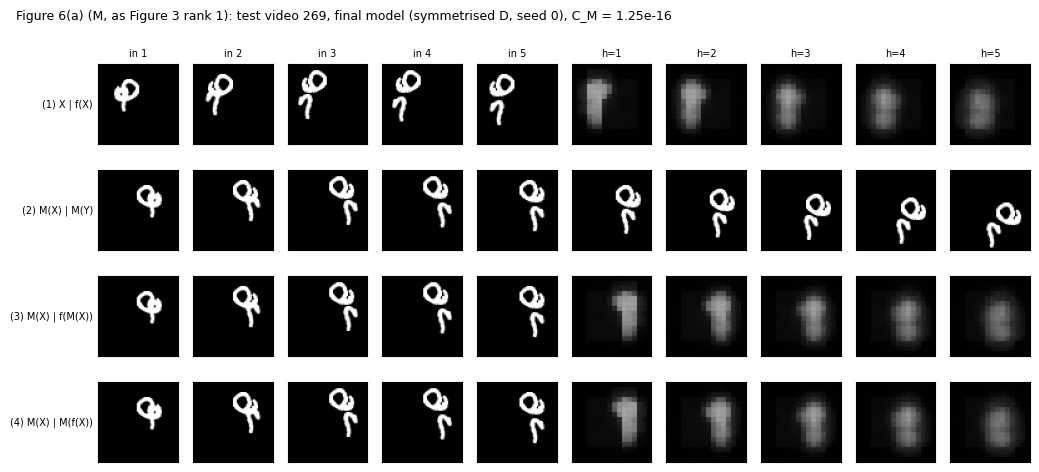

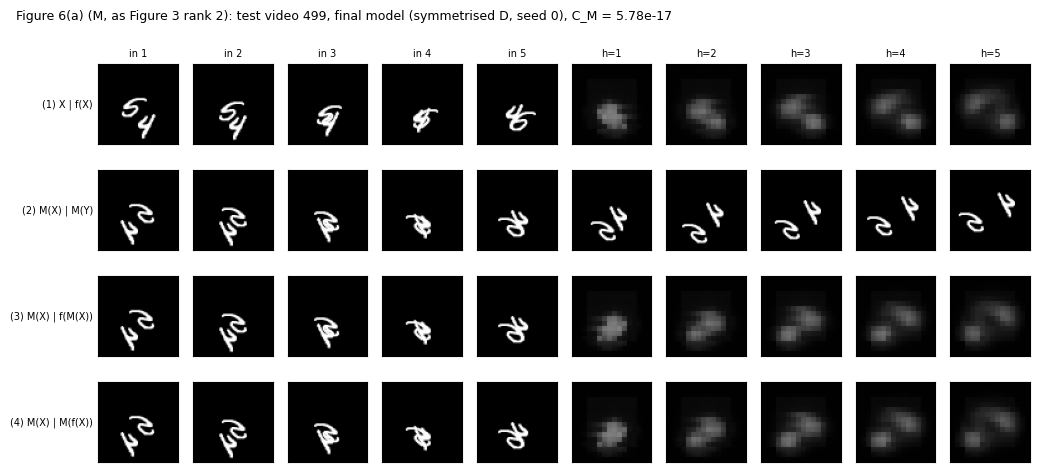

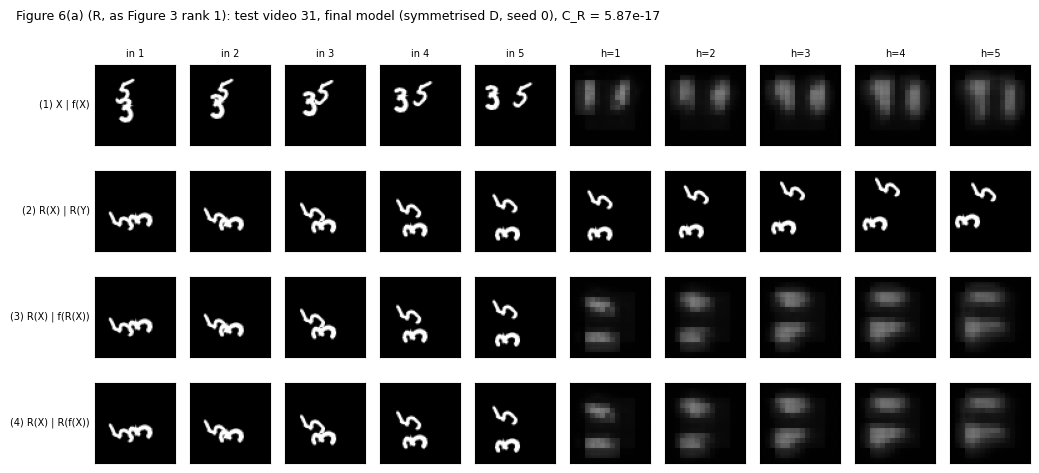

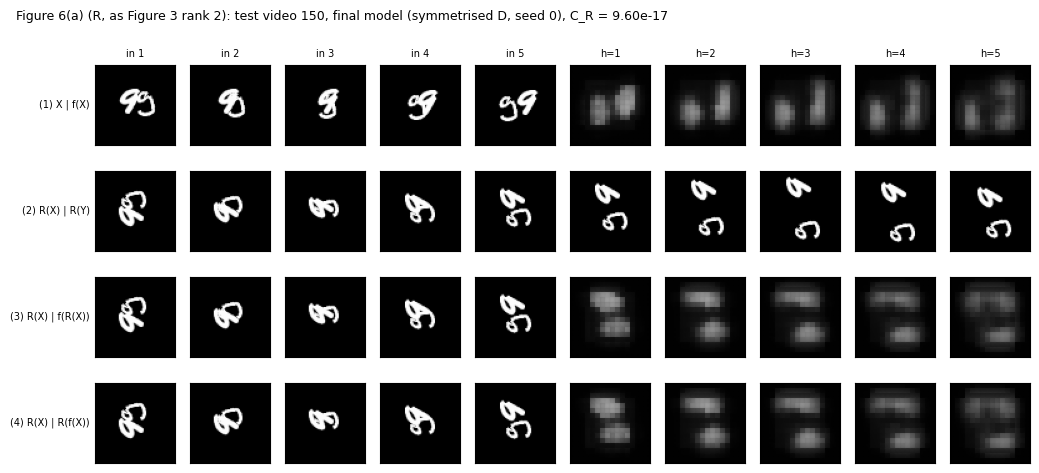

GIFs (put these paths in the Figure 6 caption):
  gifs/figure6a_M_rank1_video269.gif
  gifs/figure6a_M_rank2_video499.gif
  gifs/figure6a_R_rank1_video31.gif
  gifs/figure6a_R_rank2_video150.gif


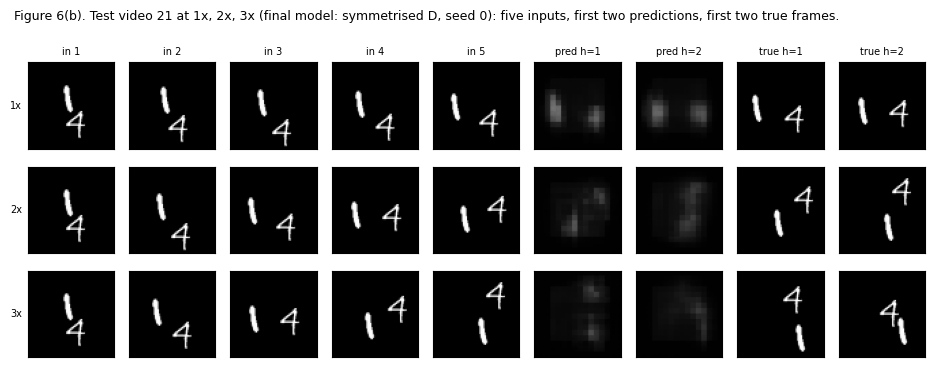

In [10]:
if FINAL_BASE not in MODELS:
    raise SystemExit(f"The final model's base ({FINAL_BASE}) is not loaded. Add its checkpoints to the input and run from Section 1.")
fig_path = find_file("figure_videos.json")
if fig_path:
    saved = json.load(open(fig_path))
    FIG3_PANELS = [tuple(p) for p in saved["fig3"]]; FIG5_VIDEO = saved["fig5"]
    print("video numbers taken from", fig_path)
print("Figure 3 panels:", FIG3_PANELS, "| Figure 5 video:", FIG5_VIDEO)

final = symmetrise(models[(FINAL_BASE, 0)])
TS = {"M": M_T, "R": R_T}

def show_rows(rows, row_labels, col_labels, title, path, figsize_per=(1.05, 1.1)):
    nr, nc = len(rows), rows[0].shape[0]
    fig, axes = plt.subplots(nr, nc, figsize=(figsize_per[0] * nc, figsize_per[1] * nr + 0.5))
    axes = np.atleast_2d(axes)
    for r in range(nr):
        for c in range(nc):
            ax = axes[r, c]
            ax.imshow(rows[r][c, 0].cpu(), cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            if c == 0: ax.set_ylabel(row_labels[r], fontsize=7, rotation=0, ha="right", va="center")
            if r == 0 and col_labels: ax.set_title(col_labels[c], fontsize=7)
    fig.suptitle(title, fontsize=9, x=0.02, ha="left")
    plt.tight_layout(); fig.savefig(path, dpi=150, bbox_inches="tight"); plt.show()

def save_gif(rows, labels, path):
    frames = []
    for h in range(5):
        fig, axes = plt.subplots(len(rows), 1, figsize=(1.9, 1.55 * len(rows)))
        for r in range(len(rows)):
            axes[r].imshow(rows[r][5 + h, 0].cpu(), cmap="gray", vmin=0, vmax=1)
            axes[r].set_xticks([]); axes[r].set_yticks([])
            axes[r].set_ylabel(labels[r], fontsize=6, rotation=0, ha="right", va="center")
        fig.suptitle(f"horizon h = {h + 1}", fontsize=8)
        plt.tight_layout()
        buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=110, bbox_inches="tight"); plt.close(fig)
        buf.seek(0); frames.append(Image.open(buf).convert("P"))
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=700, loop=0)

@torch.no_grad()
def panel_tensors(f, v, T):
    a, m = T
    X, Y, _ = windows_from_tk(torch.tensor([v]), test_dev, torch.tensor([1]), torch.tensor([1]))
    TX, TY = apply_g(X, a, m), apply_g(Y, a, m)
    return [torch.cat([X[0], f(X)[0]]), torch.cat([TX[0], TY[0]]),
            torch.cat([TX[0], f(TX)[0]]), torch.cat([TX[0], apply_g(f(X), a, m)[0]])]

cols = [f"in {i}" for i in range(1, 6)] + [f"h={h}" for h in range(1, 6)]
fig6_gifs = []
for nm, rank, v in FIG3_PANELS:
    rows = panel_tensors(final, v, TS[nm])
    c_v = float(((rows[2][5:] - rows[3][5:]) ** 2).mean())
    labels = ["(1) X | f(X)", f"(2) {nm}(X) | {nm}(Y)", f"(3) {nm}(X) | f({nm}(X))", f"(4) {nm}(X) | {nm}(f(X))"]
    show_rows(rows, labels, cols,
              f"Figure 6(a) ({nm}, as Figure 3 rank {rank}): test video {v}, final model (symmetrised {FINAL_BASE}, seed 0), C_{nm} = {fmt_sci(c_v)}",
              os.path.join(RES_DIR, f"figure6a_{nm}_rank{rank}_video{v}.png"))
    gif = os.path.join(GIF_DIR, f"figure6a_{nm}_rank{rank}_video{v}.gif")
    save_gif(rows, ["(1) f(X)", f"(2) {nm}(Y)  truth", f"(3) f({nm}(X))", f"(4) {nm}(f(X))"], gif)
    fig6_gifs.append(f"gifs/{os.path.basename(gif)}")
print("GIFs (put these paths in the Figure 6 caption):", *fig6_gifs, sep="\n  ")

with torch.no_grad():
    rows, labels = [], []
    for k in (1, 2, 3):
        X, Y, _ = windows_from_tk(torch.tensor([FIG5_VIDEO]), test_dev, torch.tensor([1]), torch.tensor([k]))
        rows.append(torch.cat([X[0], final(X)[0, :2], Y[0, :2]]))
        labels.append(f"{k}x")
show_rows(rows, labels, [f"in {i}" for i in range(1, 6)] + ["pred h=1", "pred h=2", "true h=1", "true h=2"],
          f"Figure 6(b). Test video {FIG5_VIDEO} at 1x, 2x, 3x (final model: symmetrised {FINAL_BASE}, seed 0): five inputs, first two predictions, first two true frames.",
          os.path.join(RES_DIR, "figure6b.png"))

## 7. Extra (optional, not a handout figure): the Q2.7 video, model by model

For **Q2.16** ("which change fixed which part of the failure?") it helps to see the same transformed video under each step of the story: the truth, model A, model D, and the final model. Rows show $T(X) \mid$ prediction on the transformed video.

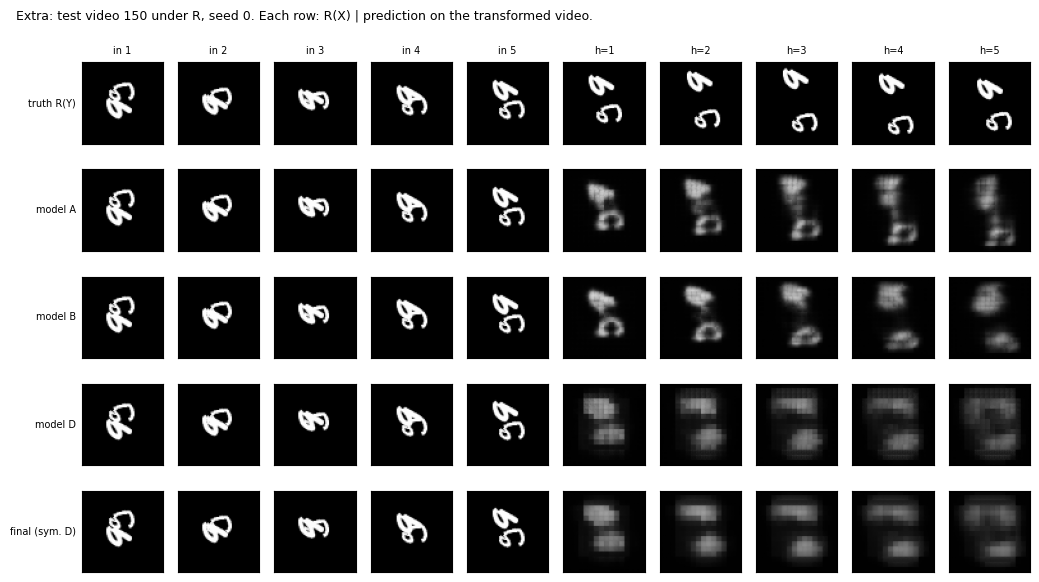

In [11]:
nm, v = Q27_VIDEO
a, m = TS[nm]
with torch.no_grad():
    X, Y, _ = windows_from_tk(torch.tensor([v]), test_dev, torch.tensor([1]), torch.tensor([1]))
    TX, TY = apply_g(X, a, m), apply_g(Y, a, m)
    rows = [torch.cat([TX[0], TY[0]])]
    labels = [f"truth {nm}(Y)"]
    for name in [n for n in ["A", "B", "D"] if n in MODELS]:
        rows.append(torch.cat([TX[0], models[(name, 0)](TX)[0]])); labels.append(f"model {name}")
    rows.append(torch.cat([TX[0], final(TX)[0]])); labels.append(f"final (sym. {FINAL_BASE})")
show_rows(rows, labels, cols, f"Extra: test video {v} under {nm}, seed 0. Each row: {nm}(X) | prediction on the transformed video.",
          os.path.join(RES_DIR, f"extra_q27_video{v}.png"))

## 8. Save everything (just run)

In [12]:
np.savez(os.path.join(RES_DIR, "ABCD_per_video.npz"), **pv)
with open(os.path.join(RES_DIR, "table5_6_summary.json"), "w") as f:
    json.dump({f"{k[0]}_seed{k[1]}": v for k, v in res.items()} | {"hardware": HARDWARE,
              "train_time_per_epoch_s": {f"{k[0]}_seed{k[1]}": v for k, v in train_time.items()}}, f, indent=1)
print("saved to", RES_DIR, ":", sorted(os.listdir(RES_DIR)))
print("GIFs in", GIF_DIR, ":", sorted(os.listdir(GIF_DIR)))

saved to /kaggle/working/results : ['ABCD_per_video.npz', 'extra_q27_video150.png', 'figure6a_M_rank1_video269.png', 'figure6a_M_rank2_video499.png', 'figure6a_R_rank1_video31.png', 'figure6a_R_rank2_video150.png', 'figure6b.png', 'reach_check.md', 'table5.md', 'table5_6_summary.json', 'table6.md']
GIFs in /kaggle/working/gifs : ['figure6a_M_rank1_video269.gif', 'figure6a_M_rank2_video499.gif', 'figure6a_R_rank1_video31.gif', 'figure6a_R_rank2_video150.gif']


## 9. What to write next (your analysis)

* **Q2.12:** describe model D (design D2) and its reach, counted as in Q2.3; the reach table in Section 2 is your check.
* **Q2.13:** label each failure (rotation, 2×, 3×) as appearance, unfamiliar motion or architectural reach, citing the Table 5 comparison that supports each label (A vs B, A vs C, C vs D).
* **Q2.14:** did any change cost accuracy at 1× ($E^{(5)}$ 1× column)? Was it worth it?
* **Q2.15:** learned symmetry (B) vs built-in symmetry (Table 6): consistency, accuracy, inference cost. Also the short argument that $\bar f$ has $C_M = C_R = 0$ for any $f$.
* **Q2.16:** back to your Q2.7 video (Figure 6(a) and the extra figure).
* **Q2.17:** final verdict, 150 words max.

Compare with your **Q2.11 predictions**, but do not edit them.